# 13 · Camera images: pixels, photons, and power

A camera records digital counts, not optical intensity in SI units. This lesson follows the calibration chain in the paper notebooks: counts to electrons, photons, energy, power, and power density.

This is the package-user version: imports come first, and each operation is introduced when the physical question calls for it.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Start with a reproducible camera-like image

A small synthetic image lets us follow units without relying on a camera file. Treat the values as analog-to-digital units (ADU) from a linear, unsaturated sensor.

In [ ]:
n = 256
pixel_m = 3.45e-6
y, x = np.mgrid[-n//2:n//2, -n//2:n//2]
image_adu = 20 + 200*np.exp(-(x**2+y**2)/(2*35**2))


## 2. Convert ADU to electrons and photons

For an idealized 8-bit camera with a 10,000-electron full well, each count represents `full_well / 255` electrons. Divide by quantum efficiency to estimate incident photons.

In [ ]:
full_well_e = 10_000
bit_depth = 8
qe = 0.80
signal_adu = np.clip(image_adu - 20, 0, None)  # subtract the synthetic dark offset
image_e = signal_adu*full_well_e/(2**bit_depth-1)
image_photons = image_e/qe


## 3. Convert photons to power density

Each photon has energy `h c / λ`. Divide by exposure time for energy-per-time, then by pixel area for power density.

In [ ]:
h_Js = 6.62607015e-34
c_ms = 299_792_458
lambda_m = 633e-9
exposure_s = 75e-6
photon_energy_J = h_Js*c_ms/lambda_m
power_W_per_pixel = image_photons*photon_energy_J/exposure_s
power_density_W_m2 = power_W_per_pixel/pixel_m**2
print(f"Peak power density: {power_density_W_m2.max():.3g} W/m²")


## Original plot code (verbatim)

The following code cells and saved outputs are copied unchanged from the cited notebook cells. Some source cells rely on variables established earlier in their original notebook.


From `paper/scaling.ipynb`, cell 2.


(500.0, 700.0)

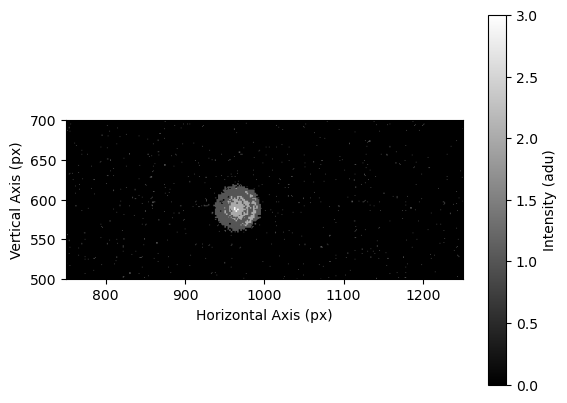

In [8]:
plt.imshow(data, cmap='gray')
plt.ylabel('Vertical Axis (px)')
plt.xlabel('Horizontal Axis (px)')
plt.colorbar(label='Intensity (adu)')
plt.xlim((750,1250))
plt.ylim((500,700))

From `paper/scaling.ipynb`, cell 4.


(500.0, 700.0)

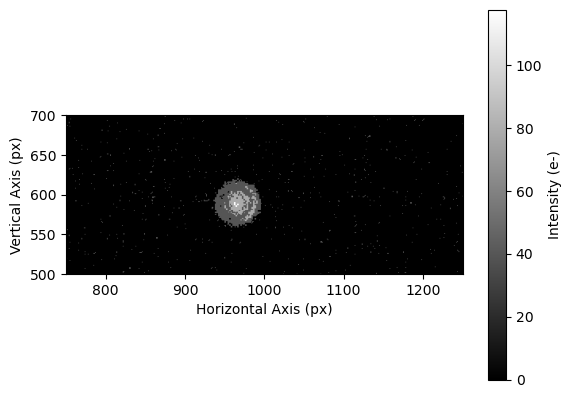

In [11]:
plt.imshow(img_electron, cmap='gray')
plt.ylabel('Vertical Axis (px)')
plt.xlabel('Horizontal Axis (px)')
plt.colorbar(label='Intensity (e-)')
plt.xlim((750,1250))
plt.ylim((500,700))

From `paper/scaling.ipynb`, cell 6.


(500.0, 700.0)

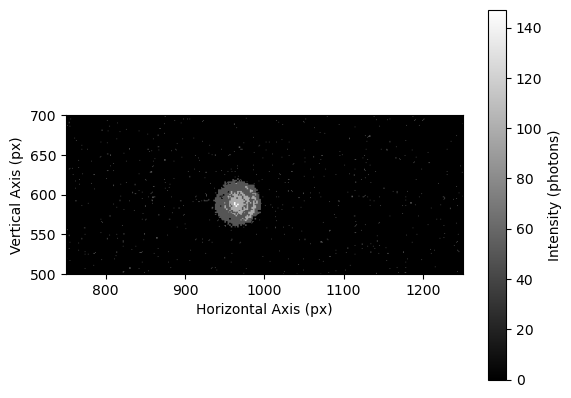

In [13]:
plt.imshow(img_photon, cmap='gray')
plt.ylabel('Vertical Axis (px)')
plt.xlabel('Horizontal Axis (px)')
plt.colorbar(label='Intensity (photons)')
plt.xlim((750,1250))
plt.ylim((500,700))

From `paper/scaling.ipynb`, cell 9.


(500.0, 700.0)

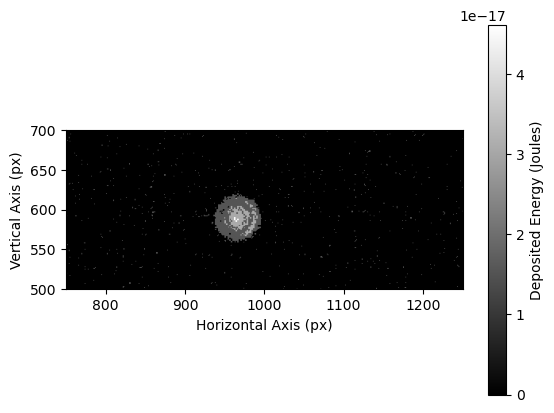

In [21]:
plt.imshow(img_J, cmap='gray')
plt.ylabel('Vertical Axis (px)')
plt.xlabel('Horizontal Axis (px)')
plt.colorbar(label='Deposited Energy (Joules)')
plt.xlim((750,1250))
plt.ylim((500,700))

From `paper/scaling.ipynb`, cell 11.


(500.0, 700.0)

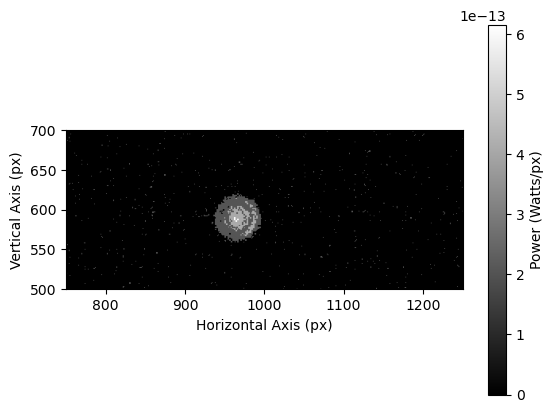

In [24]:
plt.imshow(img_power_W, cmap='gray')
plt.ylabel('Vertical Axis (px)')
plt.xlabel('Horizontal Axis (px)')
plt.colorbar(label='Power (Watts/px)')
plt.xlim((750,1250))
plt.ylim((500,700))

From `paper/scaling.ipynb`, cell 12.


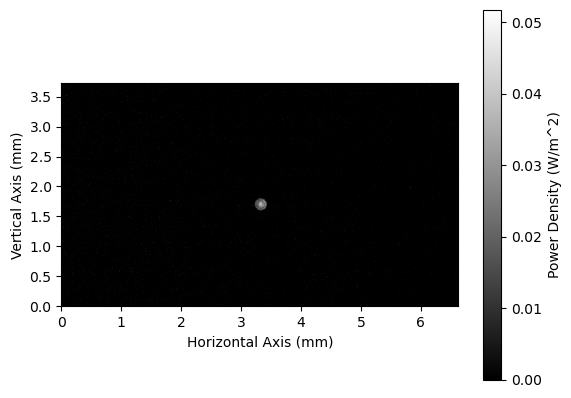

In [27]:
# power --> power density 
pixel_size_m = 3.45e-6  # Pixel size in meters (3.45 micrometers)
img_power_density_W_m2 = img_power_W / (pixel_size_m ** 2)  # Power density in W/m^2 (real def of intensity) 
x_m = np.linspace(0, img_power_density_W_m2.shape[1] * pixel_size_m, img_power_density_W_m2.shape[1])  # X-axis in meters
y_m = np.linspace(0, img_power_density_W_m2.shape[0] * pixel_size_m, img_power_density_W_m2.shape[0])  # Y-axis in meters
plt.imshow(img_power_density_W_m2, extent=(x_m[0]*1e3, x_m[-1]*1e3, y_m[0]*1e3, y_m[-1]*1e3), cmap='gray')
plt.xlabel('Horizontal Axis (mm)')
plt.ylabel('Vertical Axis (mm)')    
plt.colorbar(label='Power Density (W/m^2)')